In [1]:
# (1) import thu vien + tham so chung
import re
import math
from collections import Counter

import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

# Tham so gom chung mot cho de chinh
CONFIG = {
    "csv_path": "sentiment_data.csv",
    "seed": 42,           # co dinh de tai lap
    "max_samples": 60000, # lay bot cho nhe (data goc ~241k dong)
    "max_vocab": 15000,   # so tu giu lai trong tu dien
    "seq_len": 40,        # do dai chuoi, cat/pad ve day
    "embed_dim": 128,     # so chieu vector nhung tu (chia het cho num_heads)
    "num_heads": 4,       # so dau self-attention
    "ff_dim": 256,        # so chieu lop feed forward giua
    "num_layers": 2,      # so lop EncoderLayer xep chong
    "dropout": 0.1,       # ty le dropout chong overfit
    "num_classes": 3,     # 3 lop cam xuc: 0, 1, 2
    "batch_size": 128,
    "lr": 0.0005,
    "epochs": 8,
    "train_ratio": 0.8,
}

PAD_IDX = 0   # id cua token <pad>
UNK_IDX = 1   # id cua token <unk>

torch.manual_seed(CONFIG["seed"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device dang dung:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device dang dung: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
# (2) get data: doc file sentiment_data.csv (Comment = text, Sentiment = nhan 0/1/2)
df = pd.read_csv(CONFIG["csv_path"])[["Comment", "Sentiment"]].dropna()
print("So dong ban dau:", len(df))
print(df["Sentiment"].value_counts().sort_index())
df.head()

So dong ban dau: 240928
Sentiment
0     55105
1     82777
2    103046
Name: count, dtype: int64


,Comment,Sentiment
0,lets forget apple pay required brand new iphon...,1
1,nz retailers don’t even contactless credit car...,0
2,forever acknowledge channel help lessons ideas...,2
3,whenever go place doesn’t take apple pay doesn...,0
4,apple pay convenient secure easy use used kore...,2


In [3]:
# (3) xu ly data: tach tu -> xay tu dien -> ma hoa cau thanh day id -> chia train/test
def tokenize(text):
    # ha chu thuong, chi giu chu va so, tach theo khoang trang
    return re.findall(r"[a-z0-9]+", str(text).lower())

# Loai cau rong sau khi tokenize (vd comment toan emoji) de tranh cau toan padding
df = df[df["Comment"].apply(lambda c: len(tokenize(c)) > 0)]
df = df.sample(frac=1.0, random_state=CONFIG["seed"]).reset_index(drop=True)
df = df.iloc[:CONFIG["max_samples"]].reset_index(drop=True)

# Xay tu dien tu tap cau, giu lai max_vocab tu hay gap nhat
counter = Counter()
for cmt in df["Comment"]:
    counter.update(tokenize(cmt))
itos = ["<pad>", "<unk>"] + [w for w, _ in counter.most_common(CONFIG["max_vocab"] - 2)]
stoi = {w: i for i, w in enumerate(itos)}
vocab_size = len(itos)

# Ma hoa 1 cau thanh day id, cat hoac pad ve dung seq_len
def encode(text):
    ids = [stoi.get(tok, UNK_IDX) for tok in tokenize(text)]
    ids = ids[:CONFIG["seq_len"]]
    ids = ids + [PAD_IDX] * (CONFIG["seq_len"] - len(ids))
    return ids

X = torch.tensor([encode(c) for c in df["Comment"]], dtype=torch.long)
y = torch.tensor(df["Sentiment"].values, dtype=torch.long)

# Chia train/test
n_train = int(len(X) * CONFIG["train_ratio"])
X_train, y_train = X[:n_train], y[:n_train]
X_test, y_test = X[n_train:], y[n_train:]
print("Kich thuoc tu dien:", vocab_size)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Kich thuoc tu dien: 15000
Train: torch.Size([48000, 40]) | Test: torch.Size([12000, 40])


In [4]:
# (4) class & ham: dung ENCODER cua Transformer TU DAU (khong dung nn.TransformerEncoder)
# Tach thanh nhieu class rieng roi ghep vao class chinh o duoi cung.

class PositionalEncoding(nn.Module):
    """Them vector vi tri (sinusoidal) vao embedding.

    Self-attention khong biet thu tu tu, nen phai cong them thong tin vi tri:
      PE(pos, 2i)   = sin(pos / 10000^(2i/d))
      PE(pos, 2i+1) = cos(pos / 10000^(2i/d))
    """
    def __init__(self, embed_dim, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, embed_dim)                     # (max_len, embed_dim)
        pos = torch.arange(0, max_len).unsqueeze(1).float()      # (max_len, 1)
        div_term = torch.exp(torch.arange(0, embed_dim, 2).float()
                             * (-math.log(10000.0) / embed_dim))
        pe[:, 0::2] = torch.sin(pos * div_term)   # cot chan dung sin
        pe[:, 1::2] = torch.cos(pos * div_term)   # cot le dung cos
        self.register_buffer("pe", pe.unsqueeze(0))   # luu kem model, khong hoc

    def forward(self, x):
        # x: (batch, seq_len, embed_dim) -> cong PE cua dung seq_len dau
        return x + self.pe[:, :x.size(1)]


class MultiHeadSelfAttention(nn.Module):
    """Self-attention nhieu dau: Attention(Q,K,V) = softmax(Q K^T / sqrt(d_k)) V."""
    def __init__(self, embed_dim, num_heads):
        super().__init__()
        assert embed_dim % num_heads == 0, "embed_dim phai chia het cho num_heads"
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        # 3 phep chieu tao Q, K, V va 1 phep chieu ghep dau ra
        self.W_q = nn.Linear(embed_dim, embed_dim)
        self.W_k = nn.Linear(embed_dim, embed_dim)
        self.W_v = nn.Linear(embed_dim, embed_dim)
        self.W_o = nn.Linear(embed_dim, embed_dim)

    def forward(self, x, mask=None):
        batch, seq_len, embed_dim = x.shape

        # (batch, seq_len, embed) -> (batch, num_heads, seq_len, head_dim)
        def split_heads(t):
            t = t.view(batch, seq_len, self.num_heads, self.head_dim)
            return t.transpose(1, 2)

        Q = split_heads(self.W_q(x))
        K = split_heads(self.W_k(x))
        V = split_heads(self.W_v(x))

        # Diem tuong dong Q.K^T chia sqrt(head_dim) cho on dinh gradient
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.head_dim)

        # mask padding -> so am rat lon (dung -1e9 thay -inf de tranh NaN)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)

        attn = torch.softmax(scores, dim=-1)   # trong so chu y (tong = 1)
        context = torch.matmul(attn, V)        # (batch, num_heads, seq_len, head_dim)

        # Ghep cac dau lai -> (batch, seq_len, embed_dim)
        context = context.transpose(1, 2).contiguous().view(batch, seq_len, embed_dim)
        return self.W_o(context)


class PositionwiseFeedForward(nn.Module):
    """Feed forward ap dung doc lap cho tung vi tri (2 lop Linear + ReLU)."""
    def __init__(self, embed_dim, ff_dim):
        super().__init__()
        self.fc1 = nn.Linear(embed_dim, ff_dim)   # mo rong chieu
        self.fc2 = nn.Linear(ff_dim, embed_dim)   # nen ve lai
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.fc2(self.relu(self.fc1(x)))


class EncoderLayer(nn.Module):
    """Mot lop Encoder = Self-Attention + Feed Forward, moi khoi co residual + LayerNorm."""
    def __init__(self, embed_dim, num_heads, ff_dim, dropout):
        super().__init__()
        self.attn = MultiHeadSelfAttention(embed_dim, num_heads)
        self.ff = PositionwiseFeedForward(embed_dim, ff_dim)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        # Khoi 1: self-attention + residual + chuan hoa
        attn_out = self.attn(x, mask)
        x = self.norm1(x + self.dropout(attn_out))
        # Khoi 2: feed forward + residual + chuan hoa
        ff_out = self.ff(x)
        x = self.norm2(x + self.dropout(ff_out))
        return x


class TransformerEncoderClassifier(nn.Module):
    """Encoder Transformer + dau phan loai cam xuc (luong chinh).

    Trinh tu forward:
      1. Embedding (scale sqrt(d)) -> 2. PositionalEncoding
      -> 3. N x EncoderLayer -> 4. Mean pooling (bo padding) -> 5. Linear phan loai
    """
    def __init__(self, vocab_size, cfg):
        super().__init__()
        self.embed_dim = cfg["embed_dim"]
        self.embed = nn.Embedding(vocab_size, cfg["embed_dim"], padding_idx=PAD_IDX)
        self.pos_enc = PositionalEncoding(cfg["embed_dim"], max_len=cfg["seq_len"])
        self.dropout = nn.Dropout(cfg["dropout"])
        # Xep chong num_layers lop EncoderLayer giong nhau
        self.layers = nn.ModuleList([
            EncoderLayer(cfg["embed_dim"], cfg["num_heads"], cfg["ff_dim"], cfg["dropout"])
            for _ in range(cfg["num_layers"])
        ])
        self.fc = nn.Linear(cfg["embed_dim"], cfg["num_classes"])

    @staticmethod
    def make_mask(x):
        # Danh dau vi tri KHONG phai padding: (batch, 1, 1, seq_len)
        return (x != PAD_IDX).unsqueeze(1).unsqueeze(2)

    def forward(self, x):
        mask = self.make_mask(x)
        # 1 + 2: embedding (scale) + positional encoding
        emb = self.embed(x) * (self.embed_dim ** 0.5)
        emb = self.dropout(self.pos_enc(emb))
        # 3: cho qua tung lop encoder
        out = emb
        for layer in self.layers:
            out = layer(out, mask)
        # 4: mean pooling bo qua padding (dung mask lam trong so)
        mask_f = (x != PAD_IDX).unsqueeze(-1).float()
        summed = (out * mask_f).sum(dim=1)
        count = mask_f.sum(dim=1).clamp(min=1e-9)
        pooled = summed / count
        # 5: phan loai
        return self.fc(pooled)

    # ---------- cac method ho tro hoc ----------
    @staticmethod
    def accuracy(logits, y_true):
        return (logits.argmax(dim=1) == y_true).float().mean().item()

    def train_step(self, xb, yb, loss_fn, optimizer):
        self.train()
        optimizer.zero_grad()
        logits = self(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optimizer.step()
        return loss.item(), self.accuracy(logits, yb)

    @torch.no_grad()
    def evaluate(self, X, y, loss_fn, batch_size):
        self.eval()
        total_loss, total_correct = 0.0, 0
        for i in range(0, len(X), batch_size):
            xb, yb = X[i:i + batch_size], y[i:i + batch_size]
            logits = self(xb)
            total_loss += loss_fn(logits, yb).item() * len(xb)
            total_correct += (logits.argmax(dim=1) == yb).sum().item()
        return total_loss / len(X), total_correct / len(X)

    def fit(self, X_train, y_train, X_test, y_test, cfg, loss_fn, optimizer):
        history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
        n = len(X_train)
        for epoch in range(1, cfg["epochs"] + 1):
            self.train()
            perm = torch.randperm(n, device=X_train.device)   # xao tron thu tu
            run_loss, run_correct = 0.0, 0
            for i in range(0, n, cfg["batch_size"]):
                idx = perm[i:i + cfg["batch_size"]]
                xb, yb = X_train[idx], y_train[idx]
                loss, acc = self.train_step(xb, yb, loss_fn, optimizer)
                run_loss += loss * len(xb)
                run_correct += int(acc * len(xb))
            tr_loss = run_loss / n
            tr_acc = run_correct / n
            te_loss, te_acc = self.evaluate(X_test, y_test, loss_fn, cfg["batch_size"])
            history["train_loss"].append(tr_loss)
            history["train_acc"].append(tr_acc)
            history["test_loss"].append(te_loss)
            history["test_acc"].append(te_acc)
            print(f"Epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.3f} "
                  f"| test loss {te_loss:.4f} acc {te_acc:.3f}")
        return history

In [5]:
# (5) utils: ham goi class de train va ham ve bieu do
def run_training(X_train, y_train, X_test, y_test, vocab_size, cfg, device):
    X_train, y_train = X_train.to(device), y_train.to(device)
    X_test, y_test = X_test.to(device), y_test.to(device)

    model = TransformerEncoderClassifier(vocab_size, cfg).to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])

    history = model.fit(X_train, y_train, X_test, y_test, cfg, loss_fn, optimizer)
    return model, history


def plot_history(history, cfg):
    epochs_axis = range(1, cfg["epochs"] + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(epochs_axis, history["train_loss"], label="train")
    axes[0].plot(epochs_axis, history["test_loss"], label="test")
    axes[0].set_title("Loss theo epoch")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
    axes[0].legend()

    axes[1].plot(epochs_axis, history["train_acc"], label="train")
    axes[1].plot(epochs_axis, history["test_acc"], label="test")
    axes[1].set_title("Accuracy theo epoch")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

In [6]:
# (6) main: trinh tu lam theo de - huan luyen Encoder tren tap comment
model, history = run_training(
    X_train, y_train, X_test, y_test,
    vocab_size=vocab_size, cfg=CONFIG, device=device,
)
print("\nDo chinh xac test cuoi cung:", round(history["test_acc"][-1], 3))

Epoch  1 | train loss 0.9557 acc 0.535 | test loss 0.8165 acc 0.637


Epoch  2 | train loss 0.7599 acc 0.680 | test loss 0.6848 acc 0.717


Epoch  3 | train loss 0.6526 acc 0.736 | test loss 0.6318 acc 0.745


Epoch  4 | train loss 0.5918 acc 0.767 | test loss 0.5901 acc 0.770


Epoch  5 | train loss 0.5460 acc 0.786 | test loss 0.5893 acc 0.768


Epoch  6 | train loss 0.5142 acc 0.800 | test loss 0.5643 acc 0.782


Epoch  7 | train loss 0.4858 acc 0.813 | test loss 0.5628 acc 0.794


Epoch  8 | train loss 0.4603 acc 0.823 | test loss 0.5771 acc 0.787

Do chinh xac test cuoi cung: 0.787


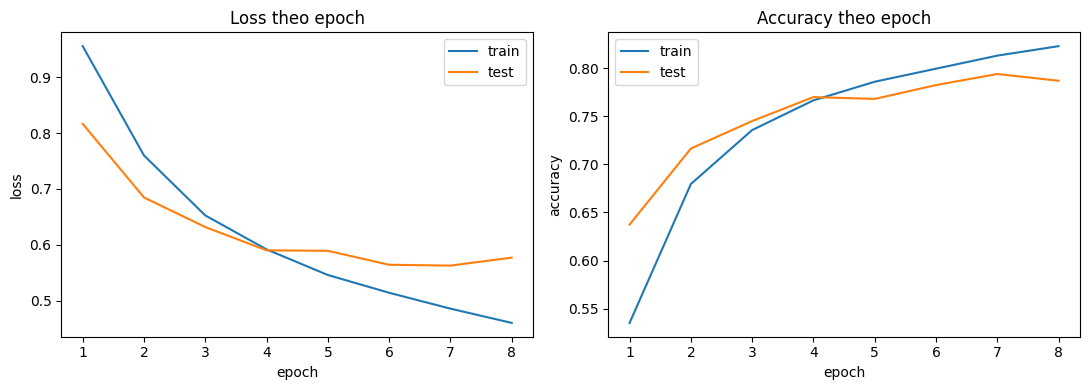

In [7]:
# (7) in/show bieu do: loss va accuracy theo epoch
plot_history(history, CONFIG)